In [1]:
!pip install -U ultralytics
import ultralytics, torch
print(ultralytics.__version__)
print(torch.cuda.is_available())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 10.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
8.4.215
True


In [2]:
from ultralytics.data.utils import check_det_dataset
from pathlib import Path
from collections import Counter

URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip"
d = check_det_dataset(URL)

print("클래스 수:", len(d["names"]))
for s in ["train", "val"]:
    lbl = Path(str(d[s]).replace("images", "labels"))
    files = list(lbl.glob("*.txt"))
    c = Counter(int(l.split()[0]) for f in files
                for l in f.read_text().splitlines() if l.strip())
    print(f"\n[{s}] 이미지 {len(files)}장")
    for k, v in sorted(c.items()):
        print(f"  {d['names'][k]:>10}: {v}")

Unzipping construction-ppe.zip to /content/datasets/construction-ppe...: 100% ━━━━━━━━━━━━ 2004/2004 291.8files/s 6.9s
클래스 수: 12

[train] 이미지 800장
      helmet: 1282
      gloves: 1548
        vest: 1476
       boots: 2003
     goggles: 612
      Person: 1962
   no_helmet: 634
   no_goggle: 265
   no_gloves: 839
    no_boots: 569
    forklift: 275
     no_vest: 437

[val] 이미지 200장
      helmet: 294
      gloves: 381
        vest: 340
       boots: 481
     goggles: 139
      Person: 481
   no_helmet: 179
   no_goggle: 82
   no_gloves: 203
    no_boots: 178
    forklift: 73
     no_vest: 130


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from ultralytics import YOLO
model = YOLO("yolo26n.pt")
model.train(data=URL, epochs=50, imgsz=640, seed=0,
            project="/content/drive/MyDrive/ppe_runs", name="e1_y26n")

Mounted at /content/drive
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, m

In [4]:
!pip install -U ultralytics
from google.colab import drive
drive.mount('/content/drive')

from ultralytics import YOLO
model = YOLO("/content/drive/MyDrive/ppe_runs/e1_y26n/weights/last.pt")
model.train(resume=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
WARNING ⚠️ model '/content/drive/MyDrive/ppe_runs/e1_y26n/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0, 16, 17, 20, 25, 58])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x797e9ad095c0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,

In [5]:
!ls /content/drive/MyDrive/ppe_runs/
!ls /content/drive/MyDrive/ppe_runs/e1_y26n/weights
!wc -l /content/drive/MyDrive/ppe_runs/e1_y26n/results.csv

e1_y26n
best.pt  last.pt
51 /content/drive/MyDrive/ppe_runs/e1_y26n/results.csv


In [6]:
from ultralytics import YOLO
URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip"
m = YOLO("/content/drive/MyDrive/ppe_runs/e1_y26n/weights/best.pt")
m.val(data=URL)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,392,408 parameters, 0 gradients, 5.4 GFLOPs
Found https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip locally at construction-ppe.zip
WARNING ⚠️ Skipping construction-ppe.zip unzip as destination path /content/datasets/construction-ppe already exists.
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4374.0±726.2 MB/s, size: 580.7 KB)
val: Scanning /content/datasets/construction-ppe/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 16.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.3it/s 5.6s
                   all        200       2961      0.861      0.688      0.749      0.535
                helmet        146        294      0.928      0.786      0.842      0.644
                gloves        136        381      0.894

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x797cfc473f50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,  

---
## ① 정답 박스 — 사람이 친 것

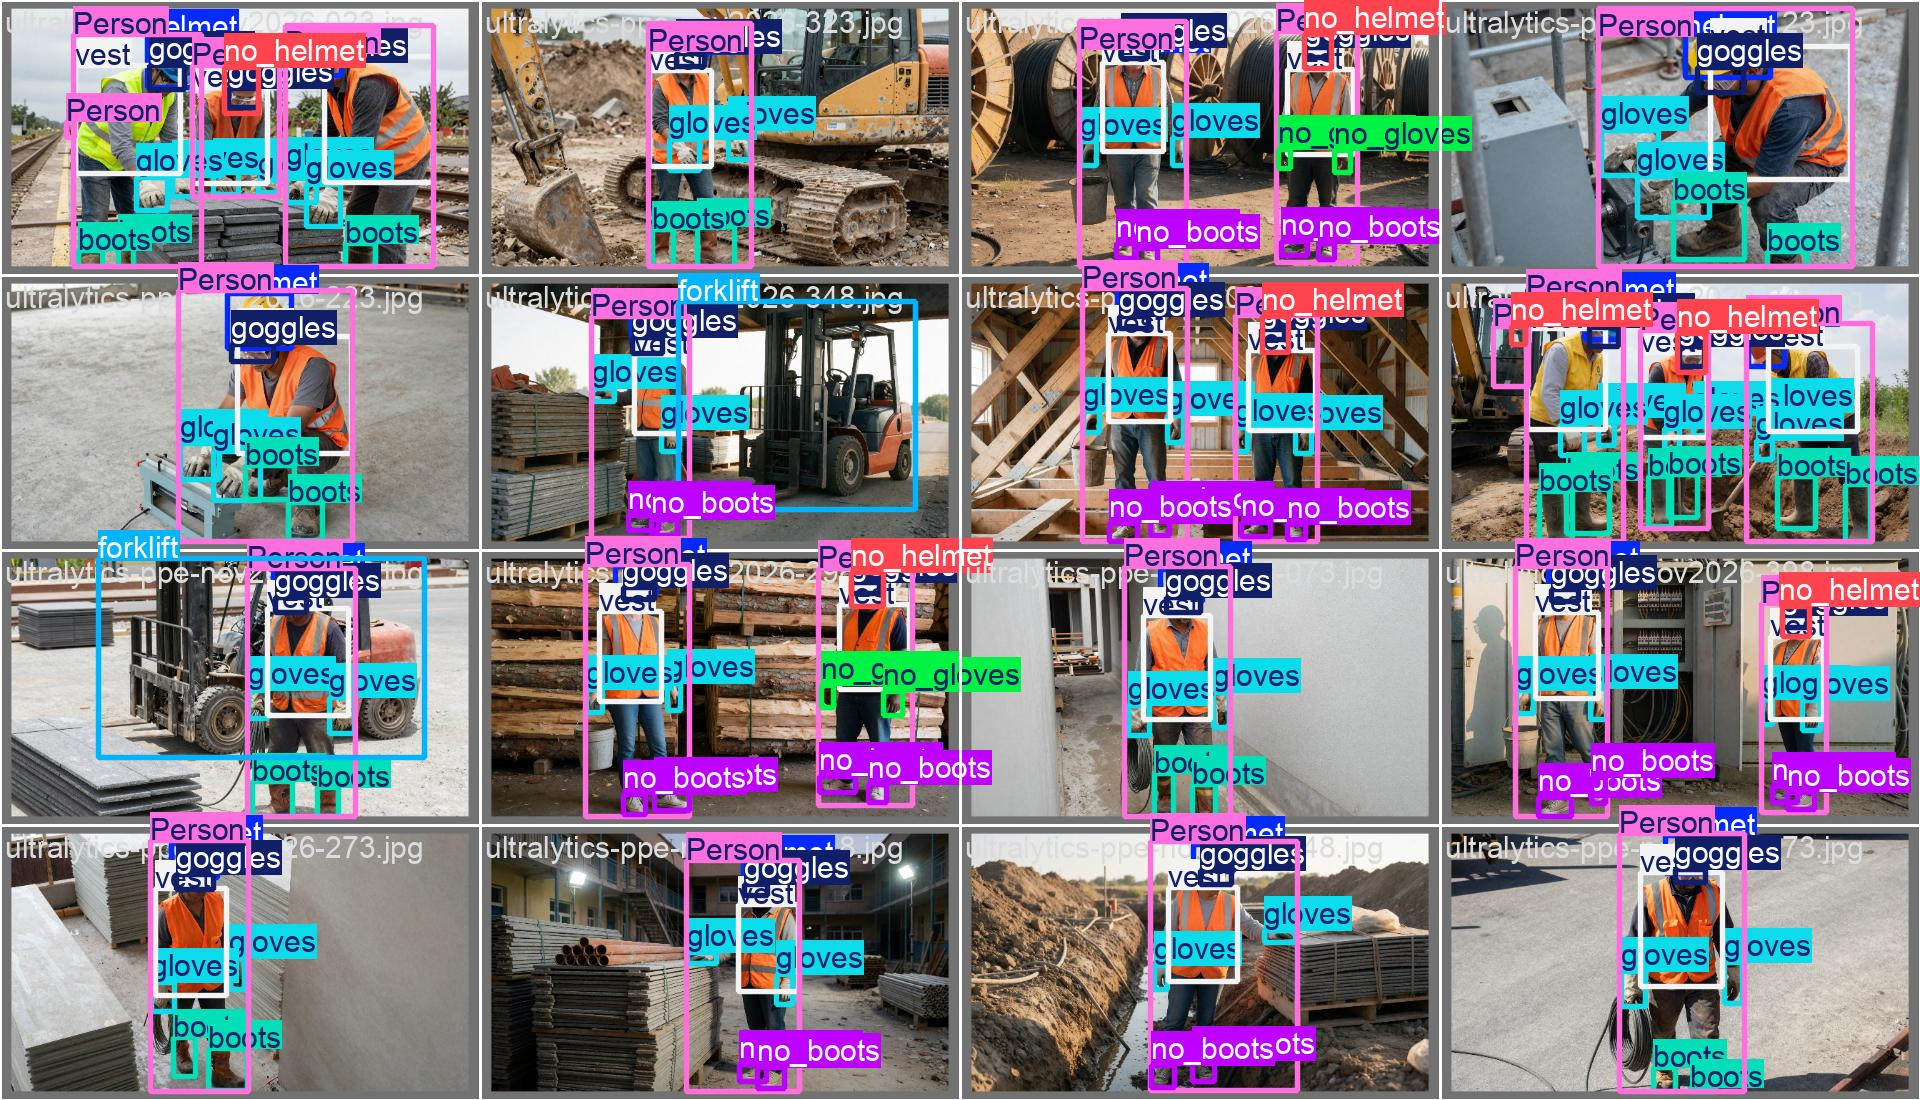

---
## ② 예측 박스 — 모델이 친 것 (숫자 = 신뢰도)

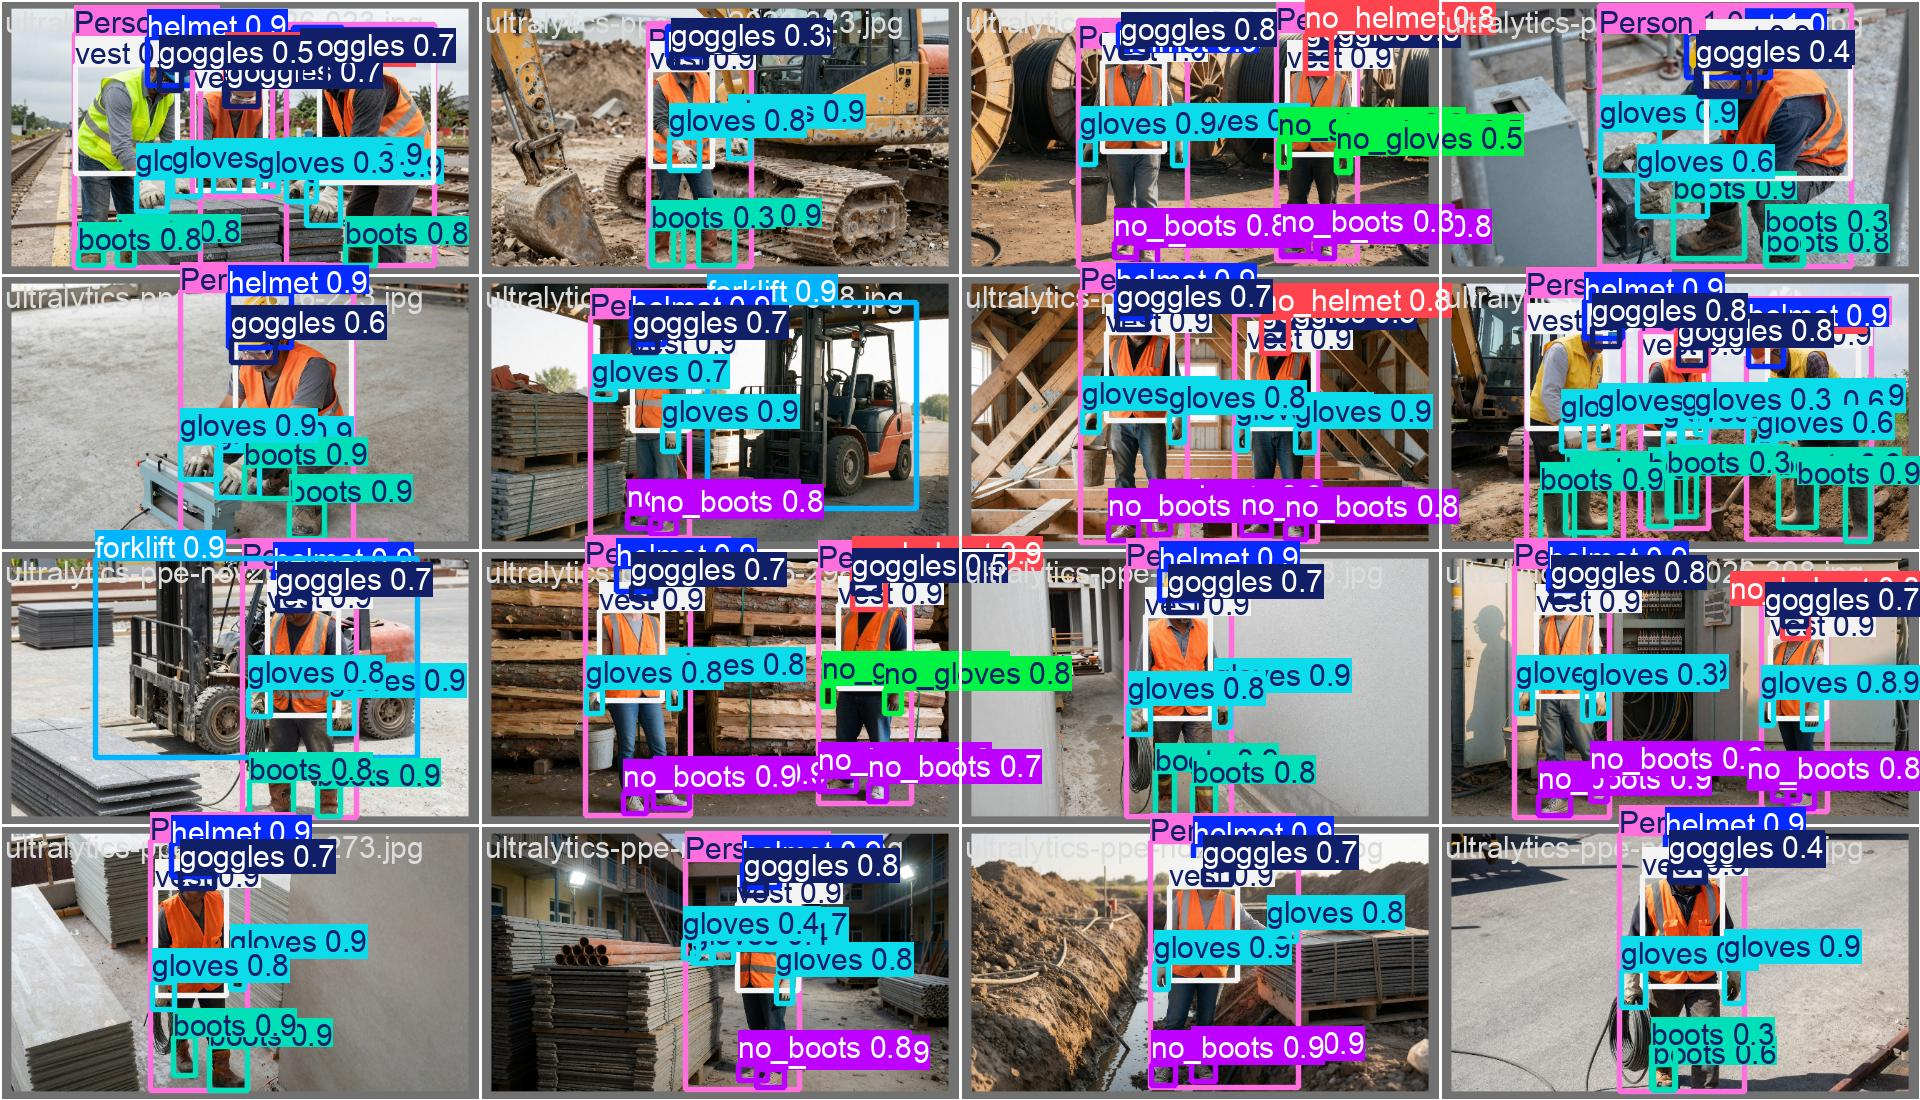

---
## ③ 혼동 행렬 — 세로 = 정답, 가로 = 모델 답

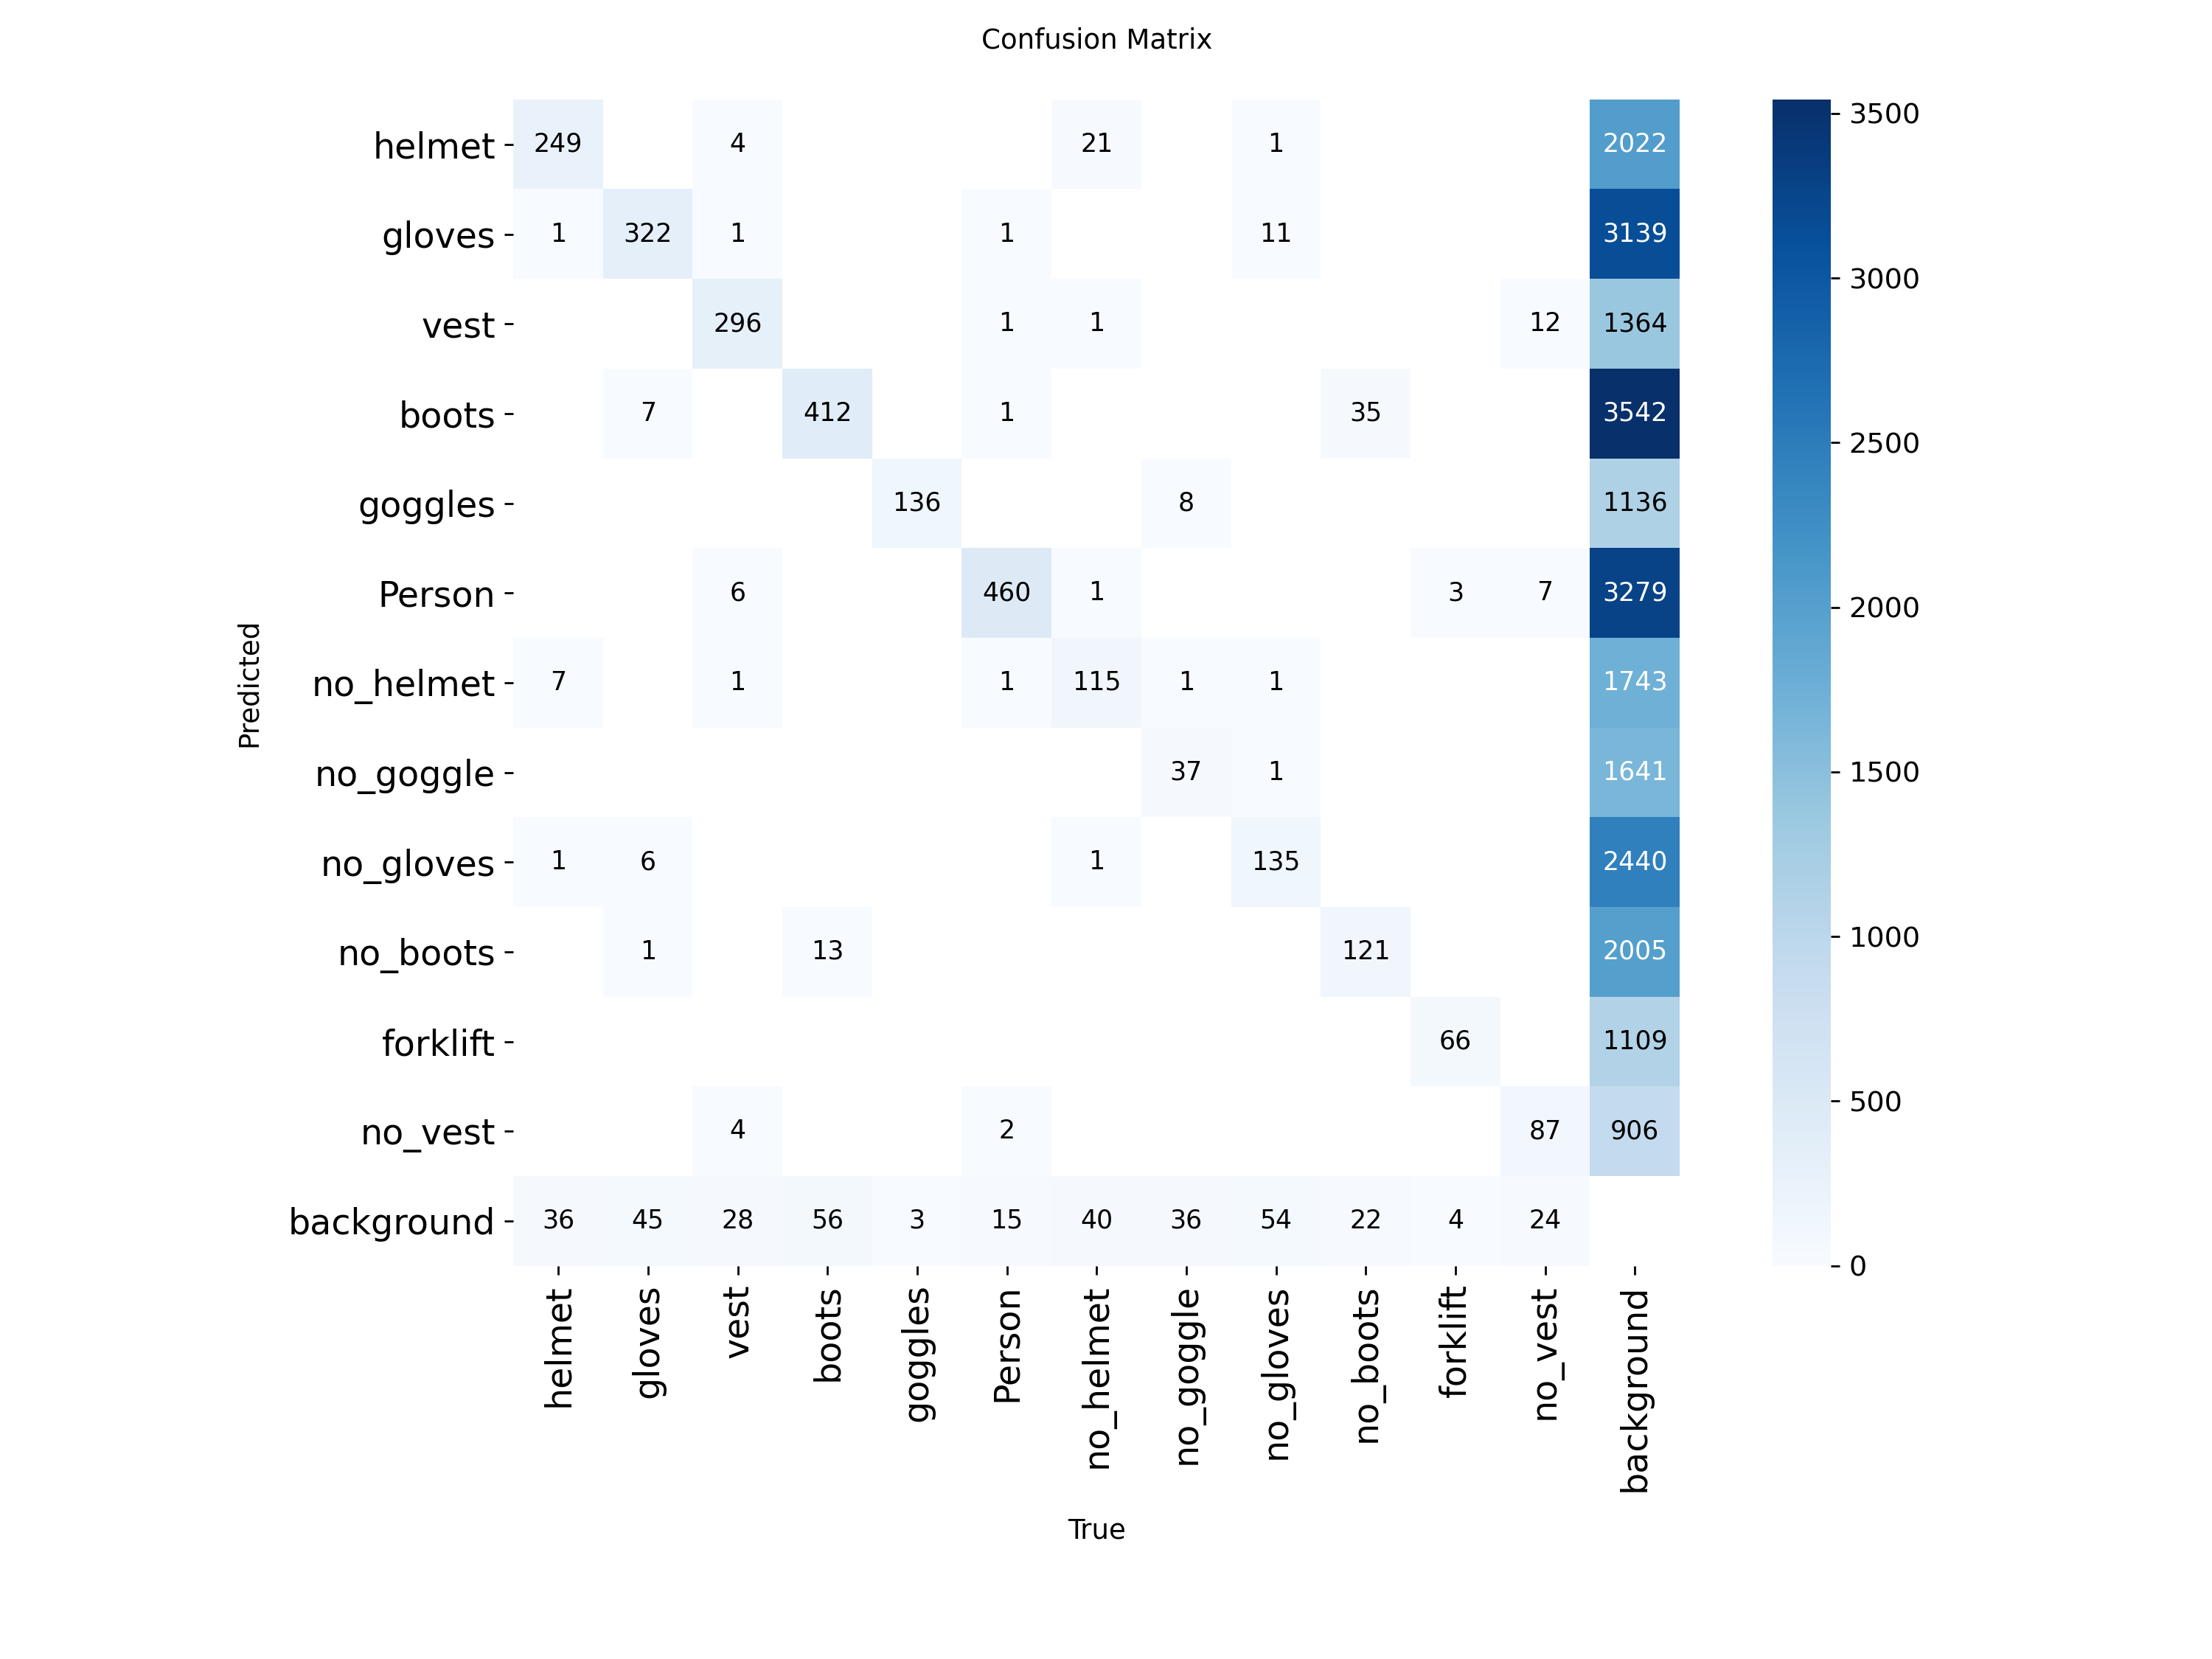

In [9]:
from IPython.display import Image, Markdown, display
import os

v = "/content/drive/MyDrive/ppe_runs/e1_val/"
if not os.path.exists(v):
    v = "/content/runs/detect/val/"

items = [
    ("① 정답 박스 — 사람이 친 것", "val_batch0_labels.jpg"),
    ("② 예측 박스 — 모델이 친 것 (숫자 = 신뢰도)", "val_batch0_pred.jpg"),
    ("③ 혼동 행렬 — 세로 = 정답, 가로 = 모델 답", "confusion_matrix.png"),
]

for title, f in items:
    display(Markdown(f"---\n## {title}"))   # 구분선 + 큰 제목
    display(Image(v + f, width=900))

In [10]:
import numpy as np, pandas as pd, torch
from pathlib import Path
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset
from torchvision.ops import box_iou

URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip"
d = check_det_dataset(URL)
img_dir = Path(d["val"])
lbl_dir = Path(str(img_dir).replace("images", "labels"))

model = YOLO("/content/drive/MyDrive/ppe_runs/e1_y26n/weights/best.pt")
name2id = {v: k for k, v in model.names.items()}
NH, H = name2id["no_helmet"], name2id["helmet"]   # 번호 대신 이름으로 찾기
CONF, IOU_T = 0.25, 0.5                            # 신뢰도 기준, 겹침 기준

out = Path("/content/drive/MyDrive/ppe_runs/e1_errors")
out.mkdir(parents=True, exist_ok=True)

def read_gt(lbl_path, w, h, cls_id):
    """라벨 txt(비율 좌표)에서 특정 클래스 정답 박스를 픽셀 좌표로 읽기"""
    boxes = []
    if lbl_path.exists():
        for line in lbl_path.read_text().splitlines():
            p = line.split()
            if len(p) >= 5 and int(p[0]) == cls_id:
                cx, cy, bw, bh = map(float, p[1:5])
                boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])
    return torch.tensor(boxes).reshape(-1, 4)

gt_rows, fp_rows = [], []
images = sorted(str(p) for p in img_dir.iterdir())

for r in model.predict(images, conf=CONF, stream=True, verbose=False):
    path = Path(r.path); h, w = r.orig_shape
    gt = read_gt(lbl_dir / (path.stem + ".txt"), w, h, NH)
    cls, xyxy, conf = r.boxes.cls.cpu().int(), r.boxes.xyxy.cpu(), r.boxes.conf.cpu()
    pred_nh, conf_nh = xyxy[cls == NH], conf[cls == NH]
    pred_h = xyxy[cls == H]

    # 짝짓기: 확신 높은 예측부터, 아직 짝 없는 정답과 IoU 0.5 이상이면 정답 처리
    matched = torch.zeros(len(gt), dtype=torch.bool)
    for i in conf_nh.argsort(descending=True).tolist():
        if len(gt):
            ious = box_iou(pred_nh[i:i+1], gt)[0]
            ious[matched] = 0
            j = int(ious.argmax())
            if ious[j] >= IOU_T:
                matched[j] = True
                continue
        fp_rows.append(dict(img=path.name, conf=float(conf_nh[i]), box=pred_nh[i].tolist()))

    # 정답 맨머리 하나하나 판정
    for j, g in enumerate(gt):
        size = float(((g[2]-g[0]) * (g[3]-g[1]) / (w*h)) ** 0.5)
        if matched[j]:
            kind = "TP"
        elif len(pred_h) and box_iou(g[None], pred_h).max() >= IOU_T:
            kind = "FN_안전모로착각"
        else:
            kind = "FN_못봄"
        gt_rows.append(dict(img=path.name, size=size, kind=kind, box=g.tolist()))

gt_df, fp_df = pd.DataFrame(gt_rows), pd.DataFrame(fp_rows)
tp = (gt_df.kind == "TP").sum()
print("정답 맨머리:", len(gt_df))
print(gt_df.kind.value_counts().to_string())
print("오탐(FP):", len(fp_df))
print(f"Recall = {tp/len(gt_df):.3f} / Precision = {tp/(tp+len(fp_df)):.3f}")

# 크기 3구간 (개수가 같도록 나눔)
gt_df["크기"], edges = pd.qcut(gt_df["size"], 3, labels=["소", "중", "대"], retbins=True)
tbl = gt_df.groupby("크기", observed=True).agg(
    개수=("kind", "size"), 미탐=("kind", lambda s: (s != "TP").sum()))
tbl["미탐률"] = (tbl.미탐 / tbl.개수).round(3)
print("\n", tbl)
print("구간 경계 (이미지 대비 크기):", edges.round(3))

gt_df.to_csv(out/"gt_no_helmet.csv", index=False)
fp_df.to_csv(out/"fp_no_helmet.csv", index=False)
tbl.to_csv(out/"size_table.csv")

Found https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip locally at construction-ppe.zip
WARNING ⚠️ Skipping construction-ppe.zip unzip as destination path /content/datasets/construction-ppe already exists.
정답 맨머리: 179
kind
TP           104
FN_못봄         63
FN_안전모로착각     12
오탐(FP): 13
Recall = 0.581 / Precision = 0.889

     개수  미탐    미탐률
크기               
소   60  51  0.850
중   59  23  0.390
대   60   1  0.017
구간 경계 (이미지 대비 크기): [      0.004       0.017       0.083       0.247]


In [12]:
def max_iou_with_gt(row):
    img = cv2.imread(str(img_dir / row.img)); h, w = img.shape[:2]
    gt = read_gt(lbl_dir / (Path(row.img).stem + ".txt"), w, h, NH)
    if len(gt) == 0:
        return 0.0
    return float(box_iou(torch.tensor([row.box]), gt).max())

fp_df["정답과_최대IoU"] = fp_df.apply(max_iou_with_gt, axis=1).round(2)
print(fp_df[["img", "conf", "정답과_최대IoU"]].to_string())

                                            img      conf  정답과_최대IoU
0   source-485eb05877af0e242d34e297d390c7cd.jpg  0.351083       0.07
1   source-485eb05877af0e242d34e297d390c7cd.jpg  0.278305       0.06
2   source-4c206d0f090805255c642a9a3d58d0e5.jpg  0.446346       0.00
3   source-56088ecf75821c1b93f4015a2bc0a071.jpg  0.328207       0.00
4   source-801ff8c7ea69847ba9cc5dcfb4df1892.jpg  0.463890       0.00
5   source-801ff8c7ea69847ba9cc5dcfb4df1892.jpg  0.359829       0.00
6   source-a8c726058fc542d983d5eb9427f86f09.jpg  0.295295       0.00
7               ultralytics-ppe-nov2026-022.jpg  0.283260       0.00
8               ultralytics-ppe-nov2026-296.jpg  0.338932       0.44
9               ultralytics-ppe-nov2026-496.jpg  0.400384       0.46
10              ultralytics-ppe-nov2026-524.jpg  0.273718       0.67
11              ultralytics-ppe-nov2026-525.jpg  0.386869       0.49
12              ultralytics-ppe-nov2026-696.jpg  0.881566       0.44



# 맨머리(no_helmet) 오탐 분석 — 총 13건
**오탐(FP)이란?** 모델이 "맨머리"라고 표시했는데, 채점 결과 정답과 맞지 않은 경우입니다.

**그림 보는 법**
- 🟥 **빨간 박스** = 모델이 "맨머리"라고 예측한 위치
- 🟩 **초록 박스** = 사람이 라벨링한 정답 맨머리 위치
- **IoU** = 두 박스가 겹친 비율 (0 = 안 겹침, 1 = 완전히 일치). **0.5 이상이어야 정답**으로 인정
- **신뢰도** = 모델이 "맨머리가 맞다"고 확신한 정도 (0~1)

**채점 기준:** 신뢰도 0.25 이상인 예측만 사용, IoU 0.5 기준


| 유형 | 건수 |
|---|---|
| ① 중복 예측 | 1 |
| ② 위치 어긋남 | 4 |
| ③ 조금만 겹침 | 2 |
| ④ 근처에 정답 없음 | 6 |

---
## ① 중복 예측 — 1건
같은 머리에 모델이 박스를 **두 번** 쳤습니다. 하나는 정답 처리됐고, 남은 하나가 오탐으로 집계됐습니다. → 모델이 맨머리를 찾긴 했으므로 **실질적 오류는 아님**.

**[10]** IoU **0.67** · 신뢰도 **0.27** · `ultralytics-ppe-nov2026-524.jpg`

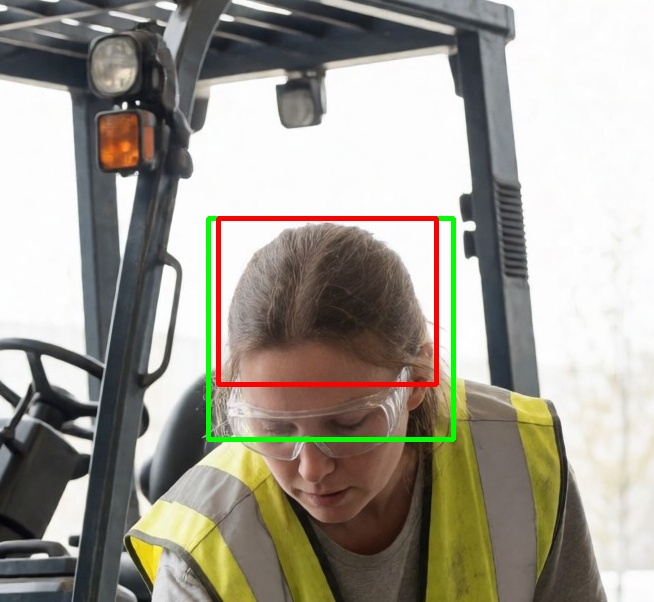

---
## ② 위치 어긋남 — 4건
정답 박스(초록)는 있는데, 모델 박스(빨강)와 겹친 비율(IoU)이 기준 0.5에 **조금 못 미쳤습니다.** → 맨머리는 맞게 찾았지만 박스 범위가 달라 틀린 것으로 채점됨. 같은 머리가 **미탐으로도 함께 집계**됐을 수 있음.

**[8]** IoU **0.44** · 신뢰도 **0.34** · `ultralytics-ppe-nov2026-296.jpg`

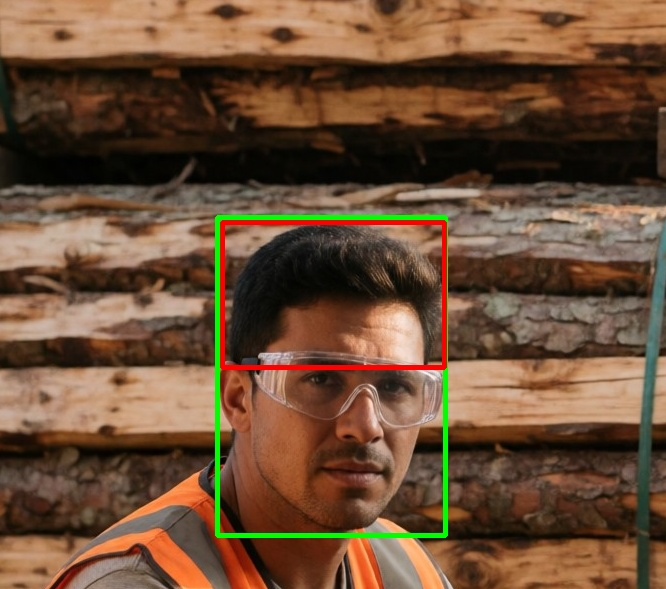

**[9]** IoU **0.46** · 신뢰도 **0.40** · `ultralytics-ppe-nov2026-496.jpg`

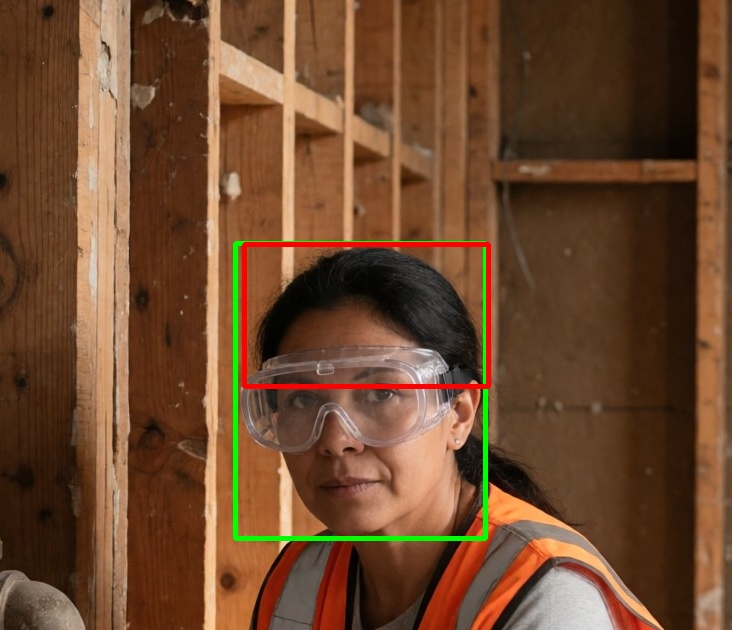

**[11]** IoU **0.49** · 신뢰도 **0.39** · `ultralytics-ppe-nov2026-525.jpg`

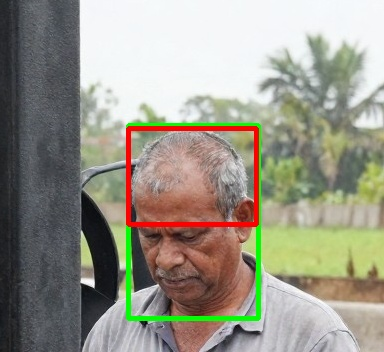

**[12]** IoU **0.44** · 신뢰도 **0.88** · `ultralytics-ppe-nov2026-696.jpg`

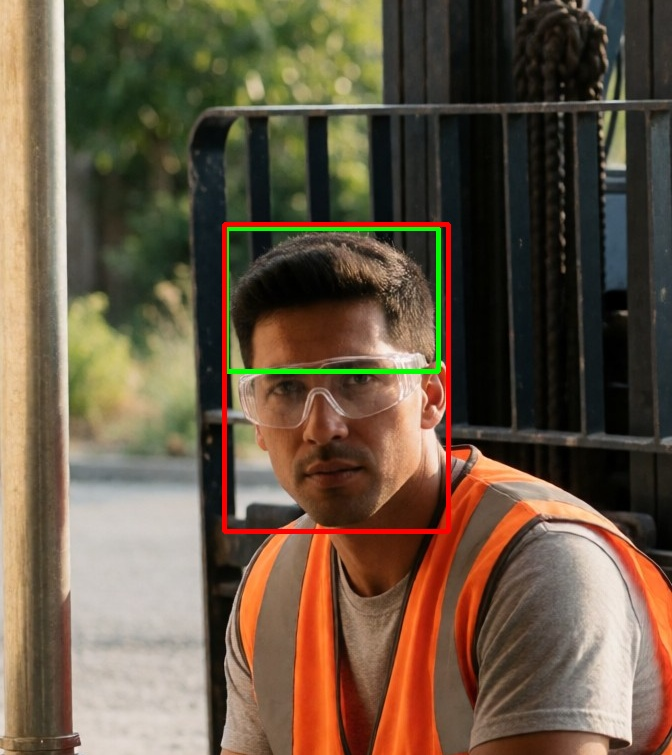

---
## ③ 조금만 겹침 — 2건
근처에 정답 박스가 있지만 거의 겹치지 않습니다. → 다른 사람의 머리를 찍었거나 엉뚱한 곳을 찍었을 수 있어 **눈으로 확인 필요**.

**[0]** IoU **0.07** · 신뢰도 **0.35** · `source-485eb05877af0e242d34e297d390c7cd.jpg`

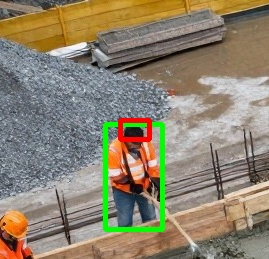

**[1]** IoU **0.06** · 신뢰도 **0.28** · `source-485eb05877af0e242d34e297d390c7cd.jpg`

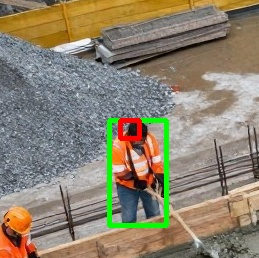

---
## ④ 근처에 정답 없음 — 6건
모델이 맨머리라고 한 곳에 정답 맨머리 박스가 **아예 없습니다.** → 빨간 박스 안이 맨머리면 **라벨 누락**(데이터 실수), 아니면 **진짜 오탐**(모델 실수).

**[2]** IoU **0.0** · 신뢰도 **0.45** · `source-4c206d0f090805255c642a9a3d58d0e5.jpg`

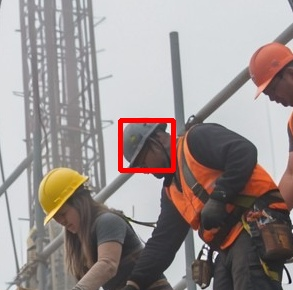

**[3]** IoU **0.0** · 신뢰도 **0.33** · `source-56088ecf75821c1b93f4015a2bc0a071.jpg`

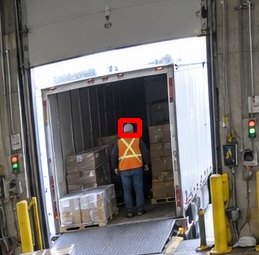

**[4]** IoU **0.0** · 신뢰도 **0.46** · `source-801ff8c7ea69847ba9cc5dcfb4df1892.jpg`

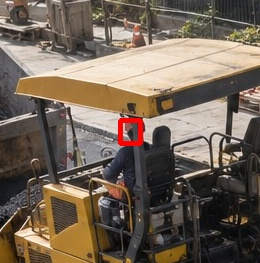

**[5]** IoU **0.0** · 신뢰도 **0.36** · `source-801ff8c7ea69847ba9cc5dcfb4df1892.jpg`

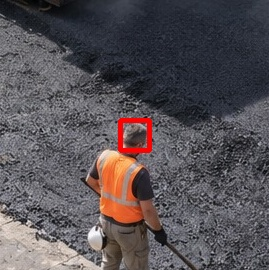

**[6]** IoU **0.0** · 신뢰도 **0.30** · `source-a8c726058fc542d983d5eb9427f86f09.jpg`

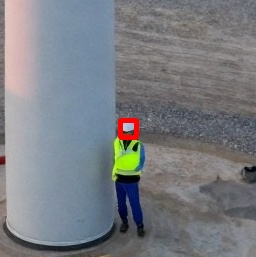

**[7]** IoU **0.0** · 신뢰도 **0.28** · `ultralytics-ppe-nov2026-022.jpg`

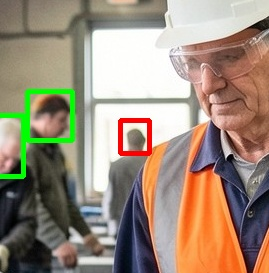

In [14]:
# ── 오탐 13건을 유형별로 나눠 설명과 함께 출력 ──
def fp_type(iou):
    if iou >= 0.5:  return "중복"
    if iou >= 0.3:  return "위치"
    if iou > 0:     return "조금"
    return "없음"

fp_df["유형"] = fp_df["정답과_최대IoU"].apply(fp_type)

GUIDE = {
    "중복": ("① 중복 예측",
             "같은 머리에 모델이 박스를 **두 번** 쳤습니다. 하나는 정답 처리됐고, 남은 하나가 오탐으로 집계됐습니다. "
             "→ 모델이 맨머리를 찾긴 했으므로 **실질적 오류는 아님**."),
    "위치": ("② 위치 어긋남",
             "정답 박스(초록)는 있는데, 모델 박스(빨강)와 겹친 비율(IoU)이 기준 0.5에 **조금 못 미쳤습니다.** "
             "→ 맨머리는 맞게 찾았지만 박스 범위가 달라 틀린 것으로 채점됨. 같은 머리가 **미탐으로도 함께 집계**됐을 수 있음."),
    "조금": ("③ 조금만 겹침",
             "근처에 정답 박스가 있지만 거의 겹치지 않습니다. "
             "→ 다른 사람의 머리를 찍었거나 엉뚱한 곳을 찍었을 수 있어 **눈으로 확인 필요**."),
    "없음": ("④ 근처에 정답 없음",
             "모델이 맨머리라고 한 곳에 정답 맨머리 박스가 **아예 없습니다.** "
             "→ 빨간 박스 안이 맨머리면 **라벨 누락**(데이터 실수), 아니면 **진짜 오탐**(모델 실수)."),
}

display(Markdown(f"""
# 맨머리(no_helmet) 오탐 분석 — 총 {len(fp_df)}건
**오탐(FP)이란?** 모델이 "맨머리"라고 표시했는데, 채점 결과 정답과 맞지 않은 경우입니다.

**그림 보는 법**
- 🟥 **빨간 박스** = 모델이 "맨머리"라고 예측한 위치
- 🟩 **초록 박스** = 사람이 라벨링한 정답 맨머리 위치
- **IoU** = 두 박스가 겹친 비율 (0 = 안 겹침, 1 = 완전히 일치). **0.5 이상이어야 정답**으로 인정
- **신뢰도** = 모델이 "맨머리가 맞다"고 확신한 정도 (0~1)

**채점 기준:** 신뢰도 0.25 이상인 예측만 사용, IoU 0.5 기준
"""))

summary = fp_df["유형"].value_counts()
display(Markdown("| 유형 | 건수 |\n|---|---|\n" +
                 "\n".join(f"| {GUIDE[k][0]} | {summary.get(k, 0)} |" for k in GUIDE)))

for key, (title, desc) in GUIDE.items():
    sub = fp_df[fp_df["유형"] == key]
    if len(sub) == 0:
        continue
    display(Markdown(f"---\n## {title} — {len(sub)}건\n{desc}"))
    for i, row in sub.iterrows():
        img = cv2.imread(str(img_dir / row.img)); h, w = img.shape[:2]
        for g in read_gt(lbl_dir / (Path(row.img).stem + ".txt"), w, h, NH).tolist():
            x1, y1, x2, y2 = map(int, g)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
        x1, y1, x2, y2 = map(int, row.box)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 255), 3)
        pad = max(120, x2 - x1)
        crop = img[max(0, y1-pad):y2+pad, max(0, x1-pad):x2+pad]
        p = out / f"fp_{key}_{i}.jpg"; cv2.imwrite(str(p), crop)
        display(Markdown(f"**[{i}]** IoU **{row['정답과_최대IoU']}** · 신뢰도 **{row.conf:.2f}** · `{row.img}`"))
        display(Image(str(p), width=320))

fp_df.to_csv(out / "fp_no_helmet_typed.csv", index=False)

In [15]:
from PIL import Image as PILImage

rows = []
for s in ["train", "val"]:
    idir = Path(d[s]); ldir = Path(str(idir).replace("images", "labels"))
    for ip in idir.iterdir():
        lp = ldir / (ip.stem + ".txt")
        if not lp.exists():
            continue
        W, Hh = PILImage.open(ip).size      # 이미지 크기 (헤더만 읽어서 빠름)
        src = "source-" if ip.stem.startswith("source-") else "ultralytics-"
        for line in lp.read_text().splitlines():
            p = line.split()
            if len(p) >= 5 and int(p[0]) == NH:
                bw, bh = float(p[3]) * W, float(p[4]) * Hh   # 픽셀 단위
                rows.append(dict(split=s, 출처=src,
                                 상대크기=(bw * bh / (W * Hh)) ** 0.5,
                                 세로가로비=bh / bw))
nh = pd.DataFrame(rows)

display(Markdown("## 출처별 no_helmet 정답 박스 비교\n"
                 "머리 박스면 세로/가로 ≈ 1, 사람 전체면 ≈ 2 이상"))
print(nh.groupby("출처").agg(
    박스수=("세로가로비", "size"),
    상대크기_중앙값=("상대크기", "median"),
    세로가로비_중앙값=("세로가로비", "median"),
    몸전체의심_비율=("세로가로비", lambda r: (r > 2).mean()),
).round(3))
nh.to_csv(out / "no_helmet_label_shape.csv", index=False)

## 출처별 no_helmet 정답 박스 비교
머리 박스면 세로/가로 ≈ 1, 사람 전체면 ≈ 2 이상

              박스수  상대크기_중앙값  세로가로비_중앙값  몸전체의심_비율
출처                                              
source-       492     0.013      1.044     0.000
ultralytics-  321     0.121      1.173     0.003


In [16]:
gt_df["출처"] = np.where(gt_df.img.str.startswith("source-"), "source-", "ultralytics-")

display(Markdown("## ① 크기 구간별 출처 구성\n"
                 "한 구간이 한 출처로만 채워져 있으면 크기 효과와 출처 효과를 구분할 수 없음"))
print(pd.crosstab(gt_df["크기"], gt_df["출처"]))

display(Markdown("## ② 출처 × 크기별 미탐률\n"
                 "같은 출처 안에서도 작을수록 미탐률이 오르면 → **크기 효과가 진짜**"))
t = (gt_df.assign(미탐=gt_df.kind != "TP")
          .groupby(["출처", "크기"], observed=True)["미탐"]
          .agg(개수="size", 미탐률="mean").round(3))
print(t)
t.to_csv(out / "miss_by_source_size.csv")

## ① 크기 구간별 출처 구성
한 구간이 한 출처로만 채워져 있으면 크기 효과와 출처 효과를 구분할 수 없음

출처  source-  ultralytics-
크기                       
소        60             0
중        36            23
대         0            60


## ② 출처 × 크기별 미탐률
같은 출처 안에서도 작을수록 미탐률이 오르면 → **크기 효과가 진짜**

                 개수    미탐률
출처           크기           
source-      소   60  0.850
             중   36  0.556
ultralytics- 중   23  0.130
             대   60  0.017
